# **Mejora 1: Cuello de botella espacial (*Spatial Bottleneck*)**

## **0. Introducción y objetivo**

En `explicacion_mejoras.ipynb` recapitulamos los resultados de la serie principal y fijamos el **Bloque 2 (arquitectura base)** como prioridad inmediata para intentar mejorar tanto la nitidez de las reconstrucciones (bajar del `FID = 61.17` obtenido en `AE_complex2_VGG`) como la estabilidad geométrica del morphing, sin disparar el coste computacional.

En este notebook implementamos el **punto 2.1: Cuello de botella espacial (*Spatial Bottleneck*)**. Se trata de una variante controlada de `AE_complex2_VGG`: mantenemos exactamente las mismas imágenes RGB de `64x64`, las mismas particiones, la misma pérdida (`L1 + (1 - SSIM) + VGG16`), la misma semilla, el mismo `Cosine Decay` y `30` épocas. La **única modificación** está en la transición al espacio latente:

- En `AE_complex2_VGG`, el tensor `4x4x256` del encoder se aplana con `Flatten()` y pasa por una capa `Dense(256)`, y el decoder hace el camino inverso con otra `Dense(4096)`.
- Aquí sustituimos ese bloque denso por una **convolución $1 \times 1$** con `16` filtros, obteniendo un latente tridimensional de forma `(4, 4, 16)`.

El número total de valores latentes sigue siendo exactamente **`256`** (`4 × 4 × 16 = 256`), por lo que la capacidad nominal del cuello de botella es la misma. Sin embargo, al conservar la cuadrícula espacial `4x4`, evitamos destruir la topología 2D del rostro y ahorramos alrededor de **2.1 millones de parámetros**.

Trabajamos de forma **determinista en la medida permitida por el entorno**: fijamos las semillas, usamos las particiones guardadas y seleccionamos siempre los mismos ejemplos. Como este experimento aún no tiene checkpoints guardados en `mejoras_autoencoders/checkpoints/`, `TRAIN_MODEL` comienza a `True`; tras el primer entrenamiento, conviene cambiarlo a `False` para reproducir métricas y visualizaciones desde disco.

---

## **1. Configuración e imports**

Importamos las mismas bibliotecas que en `AE_complex2_VGG` y resolvemos las rutas desde `mejoras_autoencoders/`. Conservamos `attrs.npy` para posibles análisis posteriores, aunque el entrenamiento utiliza `x.npy` e `ids.npy`.

Mantenemos `EPOCHS = 30`, `BATCH_SIZE = 128` y `SEED = 1234`. En lugar de `LATENT_DIM = 256` plano, definimos `LATENT_CHANNELS = 16` sobre la cuadrícula `4x4` (`4 × 4 × 16 = 256` valores en total). Los checkpoints se guardan en `mejoras_autoencoders/checkpoints/` con el nombre `mejora1_spatial_bottleneck256`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento 2.1: latente 4x4x16 = 256 valores, misma resolución y pérdida que AE_complex2_VGG.
LATENT_CHANNELS = 16
LATENT_SHAPE = (4, 4, LATENT_CHANNELS)
LATENT_DIM = int(np.prod(LATENT_SHAPE))
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = True
NOTEBOOK_NAME = "mejora1_spatial_bottleneck256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")
print(f"Latente espacial: {LATENT_SHAPE} ({LATENT_DIM} valores totales)")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed
Latente espacial: (4, 4, 16) (256 valores totales)


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

Respetamos exactamente las particiones guardadas en `data/processed` para que la comparación con `AE_complex2_VGG` sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]` porque la salida del decoder usa una sigmoide. El autoencoder aprende la identidad, por lo que la entrada y el objetivo son la misma imagen.

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


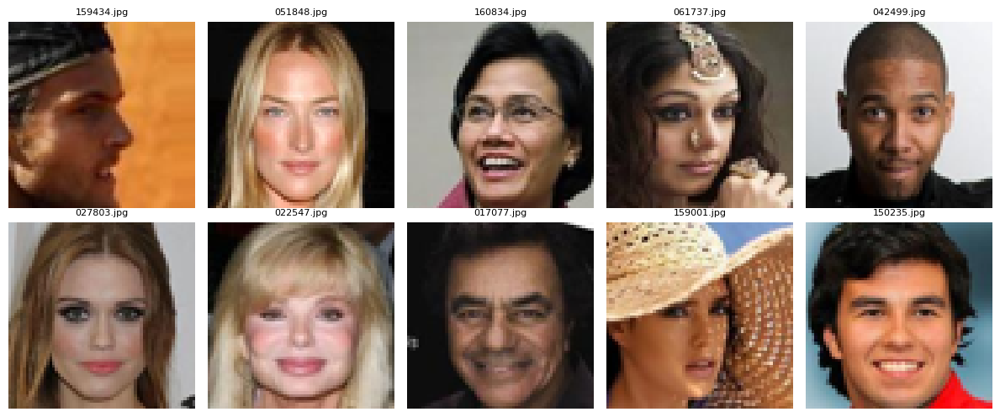

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Encoder, decoder y autoencoder con *Spatial Bottleneck***

Mantenemos las etapas convolucionales de `AE_complex2_VGG`: cuatro reducciones `Conv2D(4x4, stride=2)` en el encoder (`32, 64, 128, 256` filtros) con `BatchNormalization` y `LeakyReLU`, y cuatro bloques de `UpSampling2D(bilinear)` + `Conv2D(3x3)` en el decoder (`256, 128, 64, 32` filtros) hasta la sigmoide RGB final.

### **Qué cambia: convolución $1 \times 1$ en lugar de `Flatten` + `Dense`**

1. **En el encoder:** tras obtener el mapa `4x4x256`, en lugar de aplanarlo y conectarlo densamente a `256` neuronas, aplicamos `Conv2D(16, kernel_size=1)` con regularización `l2(1e-5)`. El resultado es un tensor espacial `(4, 4, 16)` que sigue conteniendo `256` valores, pero conserva la cuadrícula 2D del rostro.
2. **En el decoder:** recibimos el tensor `(4, 4, 16)` y lo proyectamos de vuelta a `(4, 4, 256)` con otra convolución `Conv2D(256, kernel_size=1, use_bias=False)` seguida de `BatchNormalization` y `LeakyReLU`.

### **Por qué esperamos una mejora**

- **Sesgo espacial:** una capa `Dense` mezcla todas las posiciones de la imagen entre sí. Con la convolución $1 \times 1$, cada celda de la cuadrícula `4x4` comprime y decodifica exclusivamente su propia región anatómica, lo que debería hacer más estables y ordenadas las interpolaciones.
- **Reducción de parámetros:** en `AE_complex2_VGG`, las capas densas del cuello de botella sumaban $4096 \times 256 \times 2 \approx 2.1\text{ M}$ de parámetros. Con `Conv2D(16, 1x1)` y `Conv2D(256, 1x1)` los mismos pesos se comparten en las `16` celdas espaciales y pasan a ser apenas $256 \times 16 \times 2 \approx 8\,200$ parámetros (más el sesgo de la proyección latente).

In [6]:
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (32, 64, 128, 256):
    x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

# Cuello de botella espacial: proyección 1x1 sobre 4x4x256 -> 4x4x16 (256 valores)
z = layers.Conv2D(
    LATENT_CHANNELS,
    kernel_size=1,
    padding="same",
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_spatial",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

2026-11-16 17:11:54.363474: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-16 17:11:54.363519: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-16 17:11:54.363523: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-16 17:11:54.363568: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-16 17:11:54.363584: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_spatial (Conv2D)         │ (None, 4, 4, 16)       │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 695,696 (2.65 MB)

 Trainable params: 694,736 (2.65 MB)

 Non-trainable params: 960 (3.75 KB)

En el AE_complex2_VGG eran 1.700.000 parámetros y ahora 700.000.

In [7]:
decoder_inputs = keras.Input(shape=LATENT_SHAPE, name="decoder_input")
# Recuperamos los 256 canales en cada posición de la cuadrícula 4x4 mediante Conv 1x1
x = layers.Conv2D(256, kernel_size=1, padding="same", use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 256)      │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 984,803 (3.76 MB)

 Trainable params: 983,331 (3.75 MB)

 Non-trainable params: 1,472 (5.75 KB)

En el AE original eran 2.000.000 parámetros aproximadamente.

In [8]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 4, 4, 16)       │       695,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │       984,803 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,680,499 (6.41 MB)

 Trainable params: 1,678,067 (6.40 MB)

 Non-trainable params: 2,432 (9.50 KB)

Hemos pasado de 3,785,059 a 1,680,499 parámetros totales, lo que representa una reducción de **2,104,560 parámetros** (un 55.6% menos) sin sacrificar la capacidad nominal del cuello de botella.

Cabe destacar y recordar que esto no es una idea feliz, sino la principal característica por la que destacaron las arquitecturas de **ResNet** y **GoogLeNet** (Inception).

---

## **4. Función de pérdida perceptual**

Mantenemos exactamente la misma pérdida que en `AE_complex2_VGG`, combinando fidelidad píxel a píxel (`L1`), estructura local (`1 - SSIM`) y activaciones tempranas de `VGG16` congelada (`block1_conv2` y `block2_conv2`) con peso `LAMBDA = 1e-4`:

$$L_{total} = 0.5\,L_1 + 0.5\,(1 - SSIM) + \lambda\, L_{VGG}$$

También conservamos el mismo optimizador `Adam` con `CosineDecay` de `1e-3` a `1e-5` a lo largo de `30` épocas y `EarlyStopping`. Así aislamos el efecto del cuello de botella espacial frente al `AE_complex2_VGG` original (`FID = 61.17`).

In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=full_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

Con `TRAIN_MODEL = True` entrenamos usando únicamente `train` y validamos con `val` durante un máximo de `30` épocas; `test` queda reservado para la evaluación final. Guardamos el autoencoder, el encoder, el decoder y el historial en `mejoras_autoencoders/checkpoints/`. Al cargar el modelo con `TRAIN_MODEL = False` registramos las funciones de pérdida personalizadas (`ssim_l1_loss`, `perceptual`, `full_loss`).

*(Nota: en `autoencoder.summary()` puede comprobarse que el modelo tiene alrededor de `1.7 M` de parámetros frente a los `3.8 M` de `AE_complex2_VGG`, por lo que consume menos memoria de GPU.)* 

Si hubiese problemas de memoria con la carga de datos podríamos usar tambien ImageDataGenerator con `flow_from_directory` para cargar los lotes de imágenes directamente desde disco en batches y no saturar la memoria.

In [10]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss, "perceptual": perceptual, "full_loss": full_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()

Epoch 1/30


2026-11-16 17:16:42.147350: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


469/469 ━━━━━━━━━━━━━━━━━━━━ 190s 396ms/step - loss: 0.3127 - val_loss: 0.2285
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 199s 423ms/step - loss: 0.1915 - val_loss: 0.1780
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 201s 428ms/step - loss: 0.1683 - val_loss: 0.1655
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 202s 431ms/step - loss: 0.1578 - val_loss: 0.1555
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 203s 432ms/step - loss: 0.1515 - val_loss: 0.1511
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 206s 438ms/step - loss: 0.1473 - val_loss: 0.1474
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 206s 438ms/step - loss: 0.1438 - val_loss: 0.1452
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 200s 427ms/step - loss: 0.1411 - val_loss: 0.1428
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 202s 432ms/step - loss: 0.1390 - val_loss: 0.1400
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 198s 422ms/step - loss: 0.1371 - val_loss: 0.1383
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 195s 415ms/step - loss: 0.1356 - val_loss: 0.1365
Epoch 12/30
469/469

In [11]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.121245
Val loss: 0.123166


La pérdida ha mejorado muy poco respecto a `AE_complex2_VGG`, aunque ha habido una reducción de entrenamiento de, aproximadamente, un 15%. Veamos si el FID y la geometría del morphing han mejorado en la siguiente sección.

---

## **6. Reconstrucciones en test**

Comprobamos visualmente que el autoencoder con cuello de botella espacial conserva la identidad de imágenes de `test` nunca vistas durante el entrenamiento y representamos la evolución de la pérdida de entrenamiento y validación para descartar sobreajuste. Al usar exactamente la misma función de pérdida que `AE_complex2_VGG`, los valores de `val_loss` sí son directamente comparables con los `0.1262` del modelo base.

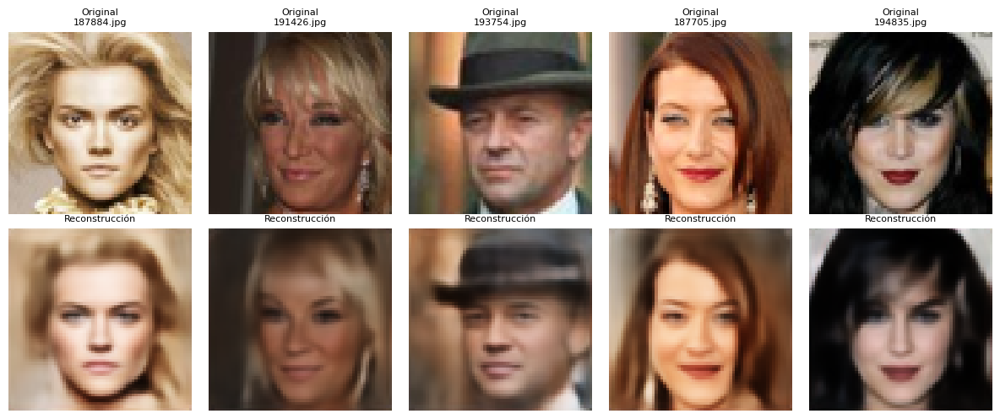

In [12]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


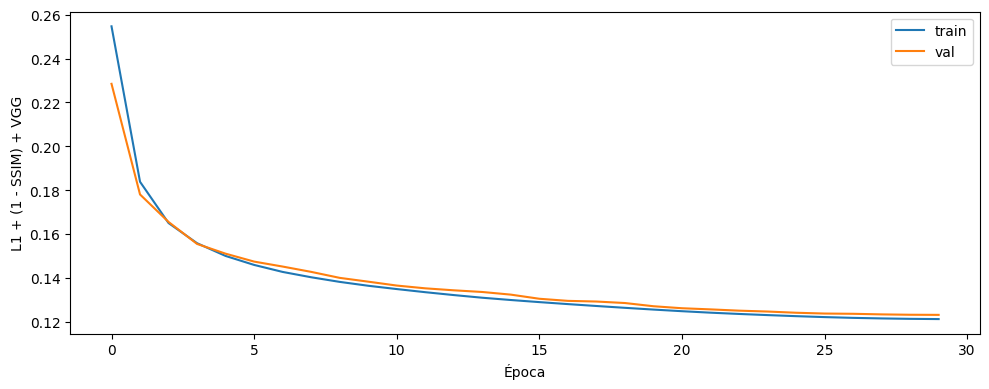

In [13]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM) + VGG")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [15]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 61.5248


El FID ha empeorado ligeramente (el anterior era de 61.1661 así que es prácticamente el mismo), aunque la reducción de parámetros y la estabilidad del morphing podrían compensarlo.

---

## **7. FID y morphing mediante interpolación en el espacio latente**

Mantenemos el mismo protocolo de FID de la serie (`1000` reconstrucciones de `test` frente a `1000` imágenes reales distintas) para comparar directamente con el `61.17` de `AE_complex2_VGG`.

Para el morphing elegimos las mismas dos imágenes de `test` (`182638.jpg` y `182640.jpg`), codificamos sus mapas latentes $z_A$ y $z_B$ de forma `(4, 4, 16)` y calculamos la interpolación lineal elemento a elemento:

$$z_\alpha = (1-\alpha) z_A + \alpha z_B, \qquad \alpha \in [0,1].$$

Al tratarse de un latente espacial, cada celda `(i, j)` de $z_A$ se interpola directamente con su celda equivalente `(i, j)` de $z_B$, preservando la alineación geométrica de los rasgos.

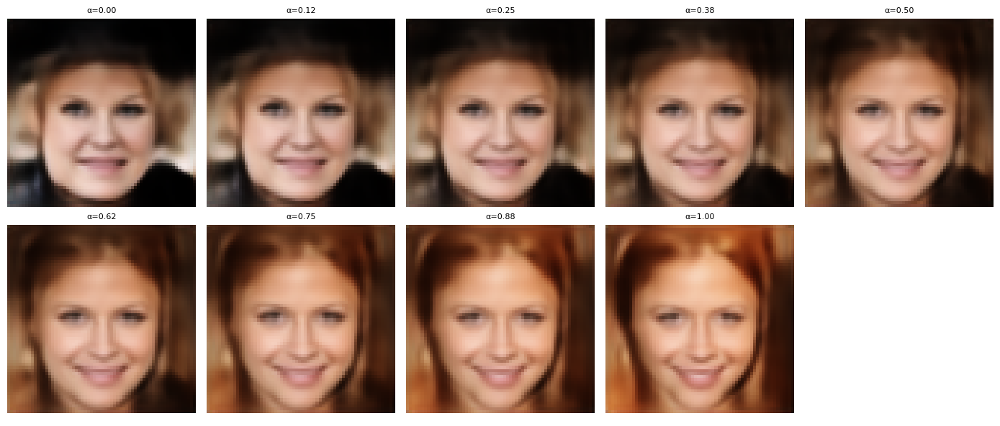

A: 182638.jpg | B: 182640.jpg


In [16]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]  # forma (4, 4, 16)
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]  # forma (4, 4, 16)
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

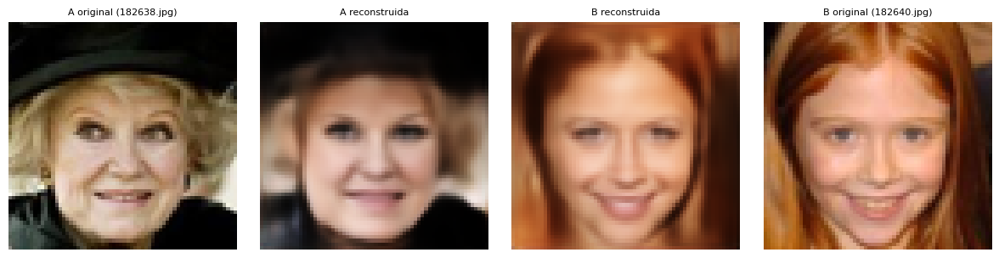

In [17]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

Repetimos la interpolación con `80` valores de $\alpha$ y guardamos los fotogramas como un GIF en `gif/fusion_mejora1_spatial256_morphing.gif`, para evaluar si los rasgos cambian gradualmente, sin saltos ni *ghosting*, y comparar visualmente con `AE_complex2_VGG`.

In [23]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_mejora1_spatial256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None, None, None]) * z_a + alphas[:, None, None, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_mejora1_spatial256_morphing.gif' | 80 fotogramas


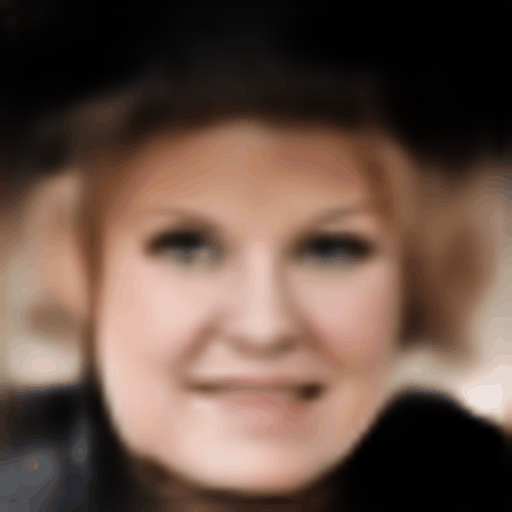

In [24]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño y criterios de evaluación**

En este experimento hemos aislado una única decisión arquitectónica del Bloque 2 de `explicacion_mejoras.ipynb`:

- **Sustituir `Flatten` + `Dense(256)` por `Conv2D(16, 1x1)` y `Conv2D(256, 1x1)`:** mantenemos los `256` valores del cuello de botella (`4 × 4 × 16`), pero conservamos la topología espacial 2D y reducimos en más de `2 millones` los parámetros del modelo respecto a `AE_complex2_VGG`.
- **Misma pérdida, datos, semilla y entrenamiento:** no tocamos nada más para poder atribuir cualquier cambio en la `val_loss` (`0.1262` en `AE_complex2_VGG`), en el `FID` (`61.17`) o en la calidad visual del GIF exclusivamente al cuello de botella espacial.

### **Qué observar tras ejecutar el entrenamiento**

1. **FID y `val_loss`:** son practicamente iguales, aunque el número de parámetros y tiempo de entrenamiento son menores.
2. **Estabilidad del morphing:** esto es complicado de evaluar sin una métrica específica. Sin embargo, se puede apreciar visualmente que esta mejora ha reducido el ghosting y los saltos de rasgos cuando dos rasgos están en posiciones cercanas o incluso en el pelo, que en este caso da un salto muy visible. 
3. **Posible limitación:** al obligar a cada celda `4x4` a comprimir solo su región local, la red pierde comunicación global directa en el cuello de botella (por ejemplo, entre el ojo izquierdo y el derecho); si esto se traduce en asimetrías al interpolar, el siguiente paso natural es el que hablamos en el bloque 2 de `explicacion_mejoras.ipynb`, por lo que en `mejora2.ipynb` desarrollaremos un módulo de atención usando este modelo como baseline.